bresenham circle drawing algo

Initial: x=0, y=8, d=-13
Iter  Pixel (x, y)   d         Next (x, y)
1     (0, 8)         -7        (1, 8)
2     (1, 8)         3         (2, 8)
3     (2, 8)         -11       (3, 7)
4     (3, 7)         7         (4, 7)
5     (4, 7)         5         (5, 6)
6     (5, 6)         11        (6, 5)

First Octant Pixels: [(0, 8), (1, 8), (2, 8), (3, 7), (4, 7), (5, 6)]


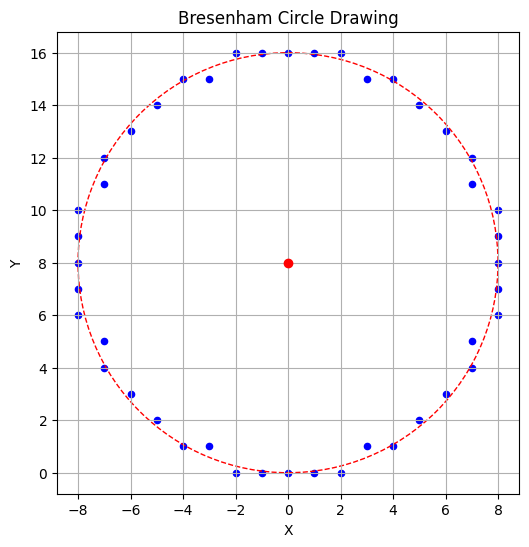

In [9]:
import matplotlib.pyplot as plt

def bresenham_circle(xc, yc, r):
    x = 0
    y = r
    d = 3 - 2 * r  # Initial decision parameter[cite: 73, 76]
    
    first_octant_pixels = []
    all_pixels = set()
    
    def add_8_symmetry(x_val, y_val):
        pts = [
            (xc + x_val, yc + y_val), (xc - x_val, yc + y_val),
            (xc + x_val, yc - y_val), (xc - x_val, yc - y_val),
            (xc + y_val, yc + x_val), (xc - y_val, yc + x_val),
            (xc + y_val, yc - x_val), (xc - y_val, yc - x_val)
        ]
        for pt in pts:
            all_pixels.add(pt)

    print(f"Initial: x={x}, y={y}, d={d}")
    print(f"{'Iter':<6}{'Pixel (x, y)':<15}{'d':<10}{'Next (x, y)'}")
    
    iteration = 1
    while x <= y:
        first_octant_pixels.append((x, y))
        add_8_symmetry(x, y)
        
        curr_x, curr_y = x, y
        
        if d < 0:
            d = d + 4 * curr_x + 6  # Slide rule: d_new = d + 4x + 6[cite: 74, 75]
            x = curr_x + 1
            y = curr_y
        else:
            d = d + 4 * (curr_x - curr_y) + 10  # Slide rule: d_new = d + 4(x - y) + 10[cite: 74, 75]
            x = curr_x + 1
            y = curr_y - 1
            
        print(f"{iteration:<6}{str((curr_x, curr_y)):<15}{d:<10}{str((x, y))}")
        iteration += 1
        
    print("\nFirst Octant Pixels:", first_octant_pixels)
    return sorted(list(all_pixels))

def plot_circle(xc, yc, r, pixels):
    plt.figure(figsize=(6, 6))
    plt.scatter([p[0] for p in pixels], [p[1] for p in pixels], color='blue', s=20)
    plt.plot(xc, yc, 'ro', label='Center')
    
    circle_ref = plt.Circle((xc, yc), r, color='red', fill=False, linestyle='--')
    plt.gca().add_patch(circle_ref)
    
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title("Bresenham Circle Drawing")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.show()

# User Input
xc = int(input("Enter center coordinate xc: "))
yc = int(input("Enter center coordinate yc: "))
r  = int(input("Enter radius r: "))

pixels = bresenham_circle(xc, yc, r)
plot_circle(xc, yc, r, pixels)

midpoint circle algo

Initial: x=0, y=5, p=-4
Iter  Pixel (x, y)   p         Next (x, y)
1     (0, 5)         -1        (1, 5)
2     (1, 5)         4         (2, 5)
3     (2, 5)         3         (3, 4)
4     (3, 4)         6         (4, 3)

First Octant Pixels: [(0, 5), (1, 5), (2, 5), (3, 4)]


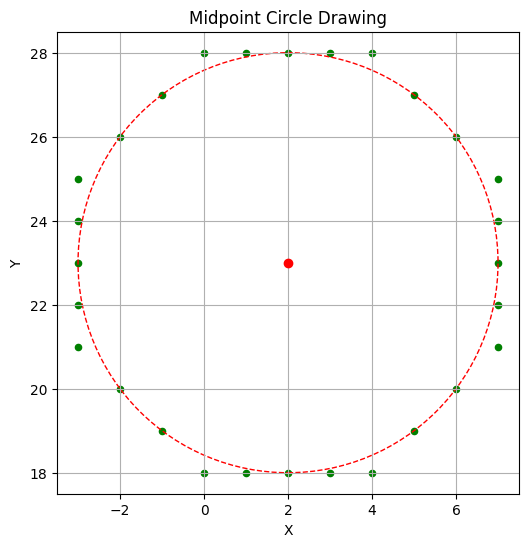

In [10]:
import matplotlib.pyplot as plt

def midpoint_circle(xc, yc, r):
    x = 0
    y = r
    p = 1 - r  # Initial decision parameter
    
    first_octant_pixels = []
    all_pixels = set()
    
    def add_8_symmetry(x_val, y_val):
        pts = [
            (xc + x_val, yc + y_val), (xc - x_val, yc + y_val),
            (xc + x_val, yc - y_val), (xc - x_val, yc - y_val),
            (xc + y_val, yc + x_val), (xc - y_val, yc + x_val),
            (xc + y_val, yc - x_val), (xc - y_val, yc - x_val)
        ]
        for pt in pts:
            all_pixels.add(pt)

    print(f"Initial: x={x}, y={y}, p={p}")
    print(f"{'Iter':<6}{'Pixel (x, y)':<15}{'p':<10}{'Next (x, y)'}")
    
    iteration = 1
    while x <= y:
        first_octant_pixels.append((x, y))
        add_8_symmetry(x, y)
        
        curr_x, curr_y = x, y
        
        if p < 0:
            x = curr_x + 1
            y = curr_y
            p = p + 2 * x + 1
        else:
            x = curr_x + 1
            y = curr_y - 1
            p = p + 2 * x + 1 - 2 * y
            
        print(f"{iteration:<6}{str((curr_x, curr_y)):<15}{p:<10}{str((x, y))}")
        iteration += 1
        
    print("\nFirst Octant Pixels:", first_octant_pixels)
    return sorted(list(all_pixels))

def plot_circle(xc, yc, r, pixels):
    plt.figure(figsize=(6, 6))
    plt.scatter([p[0] for p in pixels], [p[1] for p in pixels], color='green', s=20)
    plt.plot(xc, yc, 'ro', label='Center')
    
    circle_ref = plt.Circle((xc, yc), r, color='red', fill=False, linestyle='--')
    plt.gca().add_patch(circle_ref)
    
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title("Midpoint Circle Drawing")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.show()

# User Input
xc = int(input("Enter center coordinate xc: "))
yc = int(input("Enter center coordinate yc: "))
r  = int(input("Enter radius r: "))

pixels = midpoint_circle(xc, yc, r)
plot_circle(xc, yc, r, pixels)